# Transformée de Fourier d'une image : artefacts de bord, décomposition périodique et déquantification

Ce notebook illustre le module `eoqual.core.fourier` (eoqual-core) et l'indice de netteté de eoqual-metrics, ainsi que la note [`NOTE_TF_image.md`](../docs/NOTE_TF_image.md).

1. **Le problème** : la TFD suppose l'image périodique, ce qui crée une croix d'artefacts dans le spectre.
2. **Décomposition périodique + lisse** $u = p + s$ (Moisan).
3. **Comparaison** avec la fenêtre de Hann.
4. **Piège** : le signe du terme source.
5. **Déquantification** : la translation de $(1/2, 1/2)$ pixel, et ce que n'est pas $(-1)^{x+y}$.
6. **Axes de fréquences** et fréquence de Nyquist.
7. **Indice de netteté SI** (Blanchet & Moisan) : validation et limites d'usage.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

from eoqual.core.fourier import perdecomp, translate, dequantize, frequencies, spectrum, boundary_jump
from eoqual.metrics.nr.sharpness.backends.phase.sharpness_index import sharpness_index, sharpness_stats

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "image.interpolation": "nearest"})

def show(ax, a, title, cmap="gray", **kw):
    im = ax.imshow(a, cmap=cmap, **kw)
    ax.set_title(title)
    ax.axis("off")
    return im

def show_spec(ax, A, fy, fx, title):
    # A en log(1+|U|), axes en cycles/pixel
    ax.imshow(A, cmap="magma", extent=[fx[0], fx[-1], fy[-1], fy[0]])
    ax.set_title(title)
    ax.set_xlabel("fx (cycles/pixel)")
    ax.set_ylabel("fy (cycles/pixel)")

## 0. Image test synthétique

Image « réaliste » de 256 × 256 : un éclairage qui varie lentement (gradient, donc bords gauche/droite très différents), une texture aléatoire lisse, un disque et un motif sinusoïdal oblique de fréquence connue, $(f_x, f_y) = (0.15, 0.10)$ cycle/pixel.

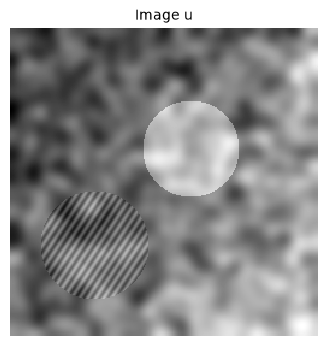

In [2]:
M = N = 256
rng = np.random.default_rng(0)
y, x = np.mgrid[0:M, 0:N].astype(float)

eclairage = 0.6 * x / N + 0.3 * y / M
texture = ndimage.gaussian_filter(rng.standard_normal((M, N)), 6)
texture *= 0.15 / texture.std()
disque = 0.4 * (((x - 150) ** 2 + (y - 100) ** 2) < 40 ** 2)
f0x, f0y = 0.15, 0.10
motif = 0.2 * np.cos(2 * np.pi * (f0x * x + f0y * y)) * (((x - 70) ** 2 + (y - 180) ** 2) < 45 ** 2)

u = eclairage + texture + disque + motif

fig, ax = plt.subplots(figsize=(4, 4))
show(ax, u, "Image u")
plt.show()

## 1. Le problème : la TFD voit l'image comme périodique

La TFD d'une image $M \times N$ est la décomposition d'un signal **périodique** de période $(M, N)$. Calculer `fft2(u)`, c'est donc analyser le pavage infini du plan par $u$. Si le bord droit ne ressemble pas au bord gauche (ou le haut au bas), ce pavage présente des **coutures** : des discontinuités verticales et horizontales.

Une marche verticale a une TF concentrée sur l'axe $f_y = 0$, avec une décroissance lente en $1/|f_x|$. Une marche horizontale donne de même l'axe $f_x = 0$. D'où la **croix** caractéristique, qui se superpose au vrai contenu fréquentiel.

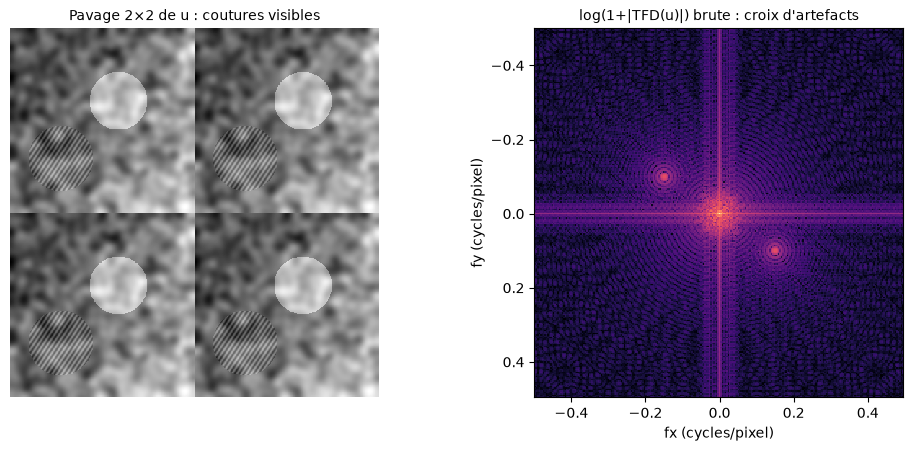

Saut moyen entre bords opposés : 0.536
Différence moyenne entre pixels voisins : 0.025


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
show(axs[0], np.tile(u, (2, 2)), "Pavage 2×2 de u : coutures visibles")
A_raw, fy, fx = spectrum(u, method="raw")
show_spec(axs[1], A_raw, fy, fx, "log(1+|TFD(u)|) brute : croix d'artefacts")
plt.tight_layout(); plt.show()
print(f"Saut moyen entre bords opposés : {boundary_jump(u):.3f}")
print(f"Différence moyenne entre pixels voisins : {np.abs(np.diff(u, axis=1)).mean():.3f}")

## 2. Décomposition périodique + lisse : $u = p + s$

`perdecomp` calcule la composante lisse $s$ en résolvant l'équation de Poisson périodique $\Delta s = v$, où $v$ ne contient que les sauts entre bords opposés. Ensuite, $p = u - s$.

* $p$ se raccorde sur le tore : plus de couture, plus de croix.
* $s$ est **lisse**, presque harmonique. Elle ne porte que la variation basse fréquence nécessaire pour absorber les sauts.
* Les détails de $u$ (bords internes, texture, motif) restent intacts dans $p$.

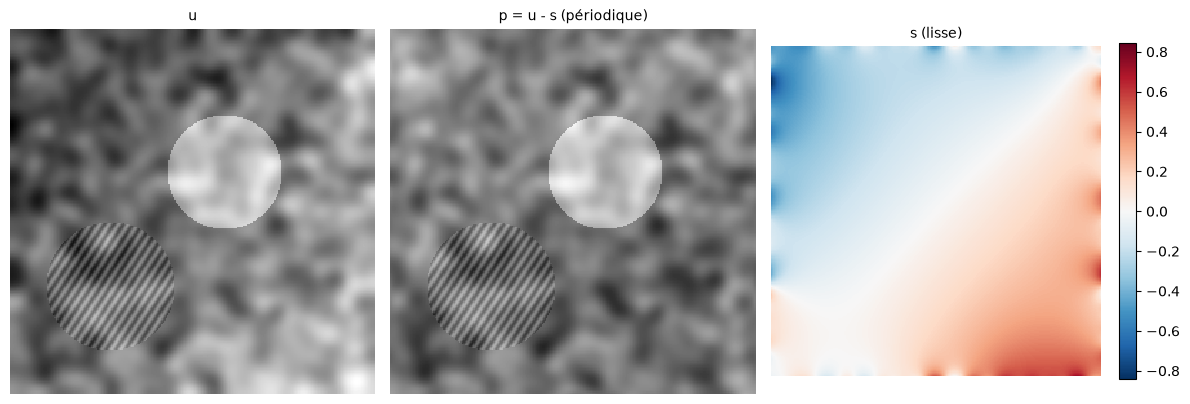

Saut aux bords  u : 0.536   p : 0.015


In [4]:
p, s = perdecomp(u)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
vmin, vmax = u.min(), u.max()
show(axs[0], u, "u", vmin=vmin, vmax=vmax)
show(axs[1], p, "p = u - s (périodique)", vmin=vmin, vmax=vmax)
lim = np.abs(s).max()
im = show(axs[2], s, "s (lisse)", cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.colorbar(im, ax=axs[2], fraction=0.046)
plt.tight_layout(); plt.show()

print(f"Saut aux bords  u : {boundary_jump(u):.3f}   p : {boundary_jump(p):.3f}")

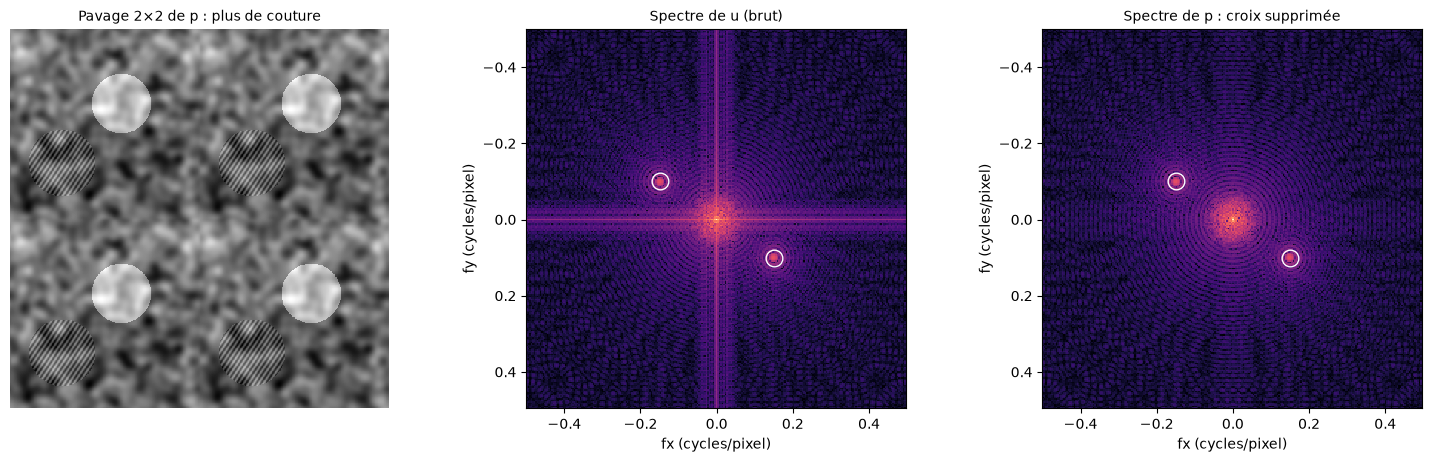

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
show(axs[0], np.tile(p, (2, 2)), "Pavage 2×2 de p : plus de couture")
A_p, _, _ = spectrum(u, method="perdecomp")
show_spec(axs[1], A_raw, fy, fx, "Spectre de u (brut)")
show_spec(axs[2], A_p, fy, fx, "Spectre de p : croix supprimée")
for ax in axs[1:]:
    ax.plot([f0x, -f0x], [f0y, -f0y], "o", mfc="none", mec="white", ms=12, mew=1)
plt.tight_layout(); plt.show()

Le motif sinusoïdal (pics entourés) est visible dans les deux spectres. Dans le spectre brut, la croix brouille cependant tout ce qui se trouve près des axes. Le profil le long de l'axe $f_y = 0$ permet de le quantifier :

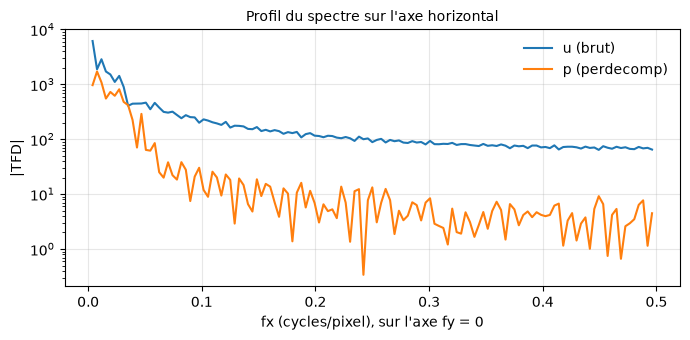

Sur l'axe fy = 0, l'amplitude moyenne est 3.7× plus forte sans perdecomp


In [6]:
A_raw_lin, _, _ = spectrum(u, method="raw", output="amplitude")
A_p_lin, _, _ = spectrum(u, method="perdecomp", output="amplitude")
i0 = M // 2
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(fx[N // 2 + 1:], A_raw_lin[i0, N // 2 + 1:], lw=1.5, label="u (brut)")
ax.semilogy(fx[N // 2 + 1:], A_p_lin[i0, N // 2 + 1:], lw=1.5, label="p (perdecomp)")
ax.set_xlabel("fx (cycles/pixel), sur l'axe fy = 0")
ax.set_ylabel("|TFD|")
ax.set_title("Profil du spectre sur l'axe horizontal")
ax.grid(alpha=0.3); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

ratio = A_raw_lin[i0, N // 2 + 1:].mean() / A_p_lin[i0, N // 2 + 1:].mean()
print(f"Sur l'axe fy = 0, l'amplitude moyenne est {ratio:.1f}× plus forte sans perdecomp")

## 3. Alternative : fenêtre de Hann

Multiplier par une fenêtre qui s'annule sur les bords supprime aussi la croix, mais :

* on **modifie l'image** partout : les bords sont écrasés et l'information qui s'y trouve est perdue ;
* le spectre est **convolué** par la TF de la fenêtre, donc les raies s'élargissent (perte de résolution fréquentielle) ;
* l'énergie est biaisée, ce qui pose problème pour les mesures quantitatives (netteté, bruit, FTM).

`perdecomp` ne retire à l'image qu'une composante lisse et ne touche ni les détails ni les raies.

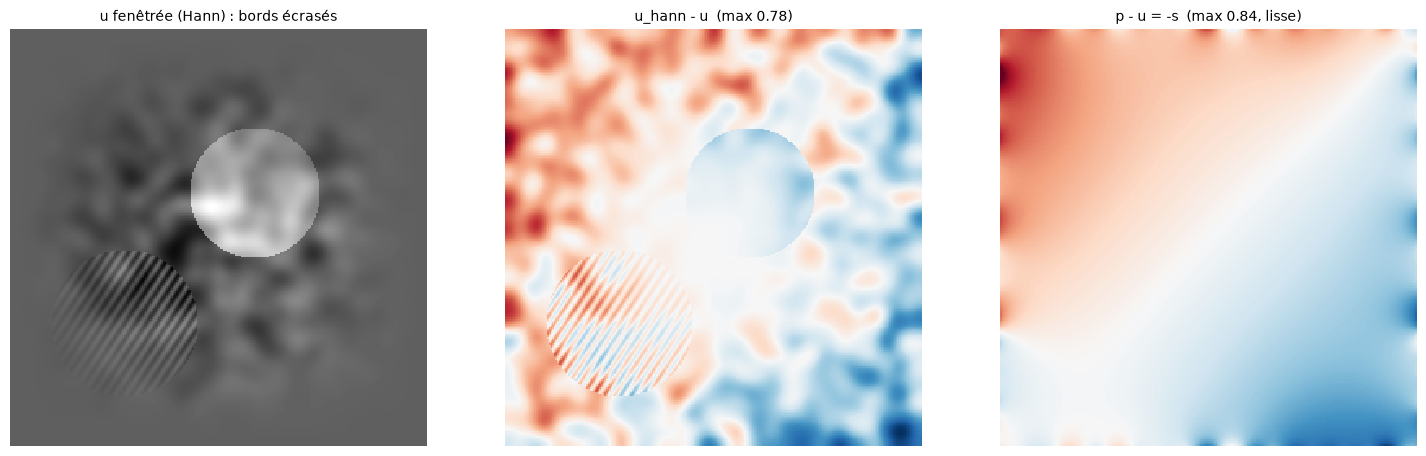

In [7]:
M_hann = np.outer(np.hanning(M), np.hanning(N))
u_hann = (u - u.mean()) * M_hann + u.mean()
A_h, _, _ = spectrum(u, method="hann")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
show(axs[0], u_hann, "u fenêtrée (Hann) : bords écrasés")
lim = np.abs(u_hann - u).max()
show(axs[1], u_hann - u, f"u_hann - u  (max {lim:.2f})", cmap="RdBu_r", vmin=-lim, vmax=lim)
show(axs[2], p - u, f"p - u = -s  (max {np.abs(s).max():.2f}, lisse)", cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.tight_layout(); plt.show()

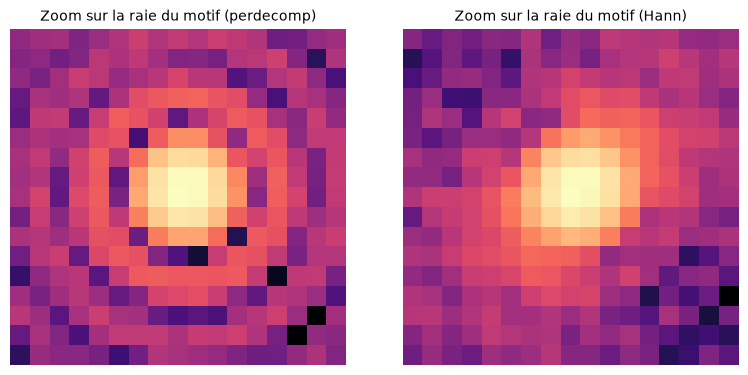

In [8]:
# Largeur de la raie du motif : zoom autour de (f0y, f0x)
iy, ix = M // 2 + round(f0y * M), N // 2 + round(f0x * N)
w = 8
fig, axs = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, A, t in [(axs[0], A_p, "perdecomp"), (axs[1], A_h, "Hann")]:
    ax.imshow(A[iy - w:iy + w + 1, ix - w:ix + w + 1], cmap="magma")
    ax.set_title(f"Zoom sur la raie du motif ({t})"); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Piège : le signe du terme source

Le terme source de l'équation de Poisson est le saut « vers l'autre côté du tore » : `u[-1] - u[0]` sur la première ligne, et non `u[0] - u[-1]`. Avec le signe inversé, on calcule $-s$, et $p = u + s$ **double** les sauts au lieu de les annuler. L'image reste plausible à l'œil, d'où l'intérêt de toujours contrôler `boundary_jump(p)`.

saut aux bords  u : 0.536
                p (signe inversé) : 1.068   <- pire que u
                p (perdecomp)     : 0.015


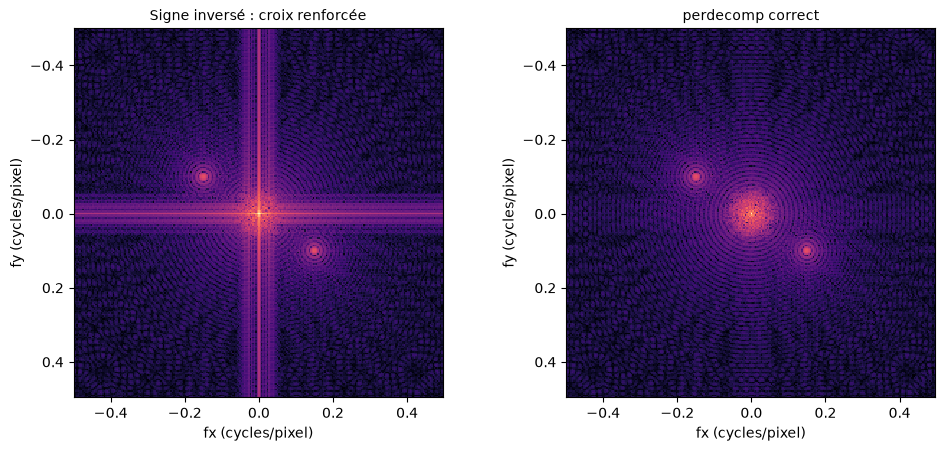

In [9]:
p_faux = u + s  # ce que donne un terme source de signe inversé
print(f"saut aux bords  u : {boundary_jump(u):.3f}")
print(f"                p (signe inversé) : {boundary_jump(p_faux):.3f}   <- pire que u")
print(f"                p (perdecomp)     : {boundary_jump(p):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
show_spec(axs[0], spectrum(p_faux, method="raw")[0], fy, fx, "Signe inversé : croix renforcée")
show_spec(axs[1], A_p, fy, fx, "perdecomp correct")
plt.tight_layout(); plt.show()

## 5. Déquantification

### 5.1 Ce que n'est pas la déquantification : $(-1)^{x+y}$

On présente parfois la multiplication par $(-1)^{x+y}$ comme un décalage de $(1/2, 1/2)$ pixel. **C'est faux.** Comme $(-1)^{x+y} = e^{i\pi x} e^{i\pi y}$, c'est une **modulation** : elle translate le *spectre* de $(N/2, M/2)$, c'est-à-dire qu'elle échange basses et hautes fréquences. C'est l'astuce classique pour centrer le spectre sans `fftshift`. L'image n'est pas déplacée et la quantification n'est pas touchée : $|u \cdot (-1)^{x+y}| = |u|$.

In [10]:
mod = u * (-1.0) ** (x + y)
print("|TFD(u·(-1)^(x+y))| == fftshift(|TFD(u)|) :",
      np.allclose(np.abs(np.fft.fft2(mod)), np.abs(np.fft.fftshift(np.fft.fft2(u)))))

|TFD(u·(-1)^(x+y))| == fftshift(|TFD(u)|) : True


### 5.2 La vraie translation de $(1/2, 1/2)$ pixel

Une translation sous-pixellique s'obtient par **interpolation de Shannon** : on multiplie la TFD par la phase $e^{-2i\pi(\xi_y/2 + \xi_x/2)}$ (`translate` / `dequantize`). Les nouvelles valeurs sont interpolées entre les pixels. Elles ne sont plus des entiers, et l'histogramme « en peigne » d'une image quantifiée disparaît.

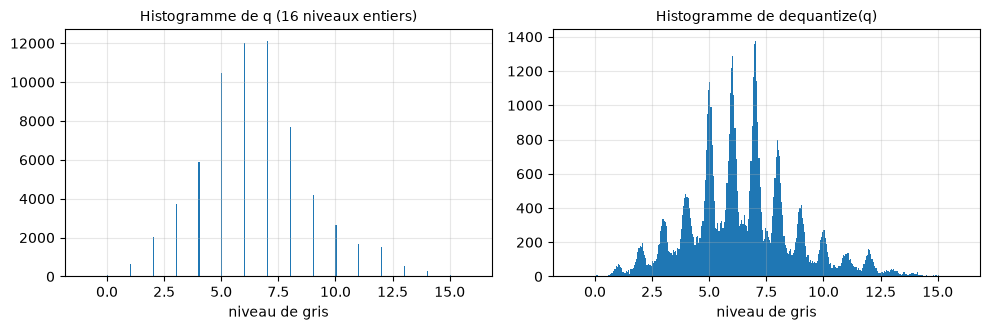

moyenne conservée : 6.4538 -> 6.4538


In [11]:
# Image quantifiée sur 16 niveaux (comme un capteur à faible dynamique)
q = np.round((p - p.min()) / np.ptp(p) * 15)
q_dq = dequantize(q)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(-1, 16, 341)
axs[0].hist(q.ravel(), bins=bins, color="C0"); axs[0].set_title("Histogramme de q (16 niveaux entiers)")
axs[1].hist(q_dq.ravel(), bins=bins, color="C0"); axs[1].set_title("Histogramme de dequantize(q)")
for ax in axs: ax.set_xlabel("niveau de gris"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"moyenne conservée : {q.mean():.4f} -> {q_dq.mean():.4f}")

Une translation ne modifie que la **phase** de la TF. Sur le spectre d'amplitude, `dequant=True` est donc sans effet, sauf sur la ligne et la colonne de Nyquist des tailles paires, où les coefficients sont atténués, voire annulés (une translation d'un demi-pixel n'y est pas représentable par une image réelle). L'option prend tout son sens avec `output="complex"`, ou pour les mesures calculées dans le domaine spatial, comme l'indice de netteté (§7).

In [12]:
A0 = spectrum(q, output="amplitude")[0]; A1 = spectrum(q, output="amplitude", dequant=True)[0]
U0 = spectrum(q, output="complex")[0];   U1 = spectrum(q, output="complex", dequant=True)[0]
modif = ~np.isclose(A0, A1)
nyquist = (np.abs(fy)[:, None] == 0.5) | (np.abs(fx)[None, :] == 0.5)
print(f"amplitude : {modif.sum()} coefficients modifiés sur {modif.size}, "
      f"tous sur la ligne/colonne de Nyquist : {np.all(nyquist[modif])}")
print(f"phase     : {(~np.isclose(U0, U1)).sum()} coefficients modifiés sur {U0.size}")

amplitude : 510 coefficients modifiés sur 65536, tous sur la ligne/colonne de Nyquist : True
phase     : 65281 coefficients modifiés sur 65536


### 5.3 Pourquoi déquantifier **après** `perdecomp`

L'interpolation de Shannon est périodique. Appliquée à $u$ non périodique, elle « voit » les coutures et produit des **oscillations de Gibbs** le long des bords. On le vérifie sur une image analytique, dont la version translatée exacte est connue :

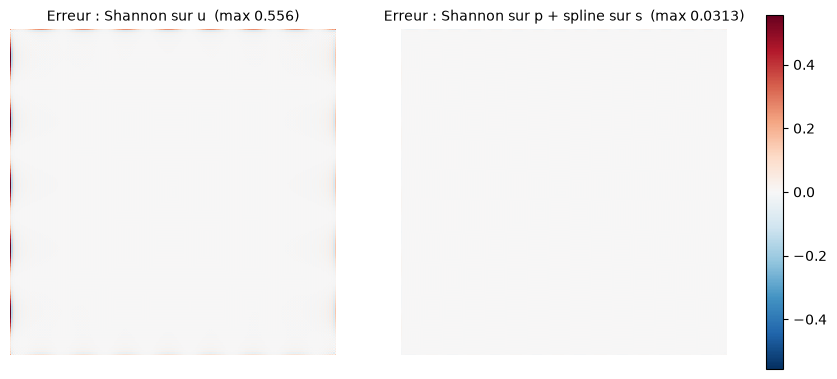

In [13]:
def f(xx, yy):  # scène continue, lisse mais non périodique sur la fenêtre
    return 0.6 * xx / N + 0.3 * yy / M + 0.3 * np.cos(2 * np.pi * (0.03 * xx + 0.02 * yy))

g = f(x, y)
vrai = f(x - 0.5, y - 0.5)  # translation exacte de (1/2, 1/2)

err_u = translate(g, 0.5, 0.5) - vrai
pg, sg = perdecomp(g)
# p : Shannon (périodique) ; s : lisse, une spline suffit
err_p = translate(pg, 0.5, 0.5) + ndimage.shift(sg, (0.5, 0.5), order=3, mode="nearest") - vrai

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
lim = np.abs(err_u).max()
show(axs[0], err_u, f"Erreur : Shannon sur u  (max {np.abs(err_u).max():.3f})", cmap="RdBu_r", vmin=-lim, vmax=lim)
im = show(axs[1], err_p, f"Erreur : Shannon sur p + spline sur s  (max {np.abs(err_p).max():.4f})",
          cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.colorbar(im, ax=axs, fraction=0.025)
plt.show()

## 6. Axes de fréquences et fréquence de Nyquist

Avec un pas d'échantillonnage de 1 pixel, la fréquence d'échantillonnage vaut 1 cycle/pixel et **la fréquence de Nyquist vaut 0.5 cycle/pixel**, quelle que soit la taille de l'image. Le spectre centré couvre $[-0.5, 0.5[$ sur chaque axe (`frequencies`). Le pic du motif tombe bien en $(0.15, 0.10)$ :

In [14]:
A_lin, fy, fx = spectrum(u, method="perdecomp", output="amplitude")
A_lin[M // 2, N // 2] = 0  # on ignore la composante continue
A_lin[np.abs(fy)[:, None] + np.abs(fx)[None, :] < 0.05] = 0  # et les très basses fréquences
iy, ix = np.unravel_index(np.argmax(A_lin), A_lin.shape)
print(f"pic détecté en (fy, fx) = ({fy[iy]:+.3f}, {fx[ix]:+.3f}) cycle/pixel ; attendu ±(0.100, 0.150)")

pic détecté en (fy, fx) = (+0.102, +0.148) cycle/pixel ; attendu ±(0.100, 0.150)


**Pièges fréquents** :

* $N/2$ est la fréquence de Nyquist en **cycles par largeur d'image**. En cycles/pixel, elle vaut toujours 0.5.
* Dans le spectre centré, le rayon `min(M, N) // 4` (en indices) correspond à **Nyquist/2** (0.25 cycle/pixel), et non à Nyquist, qui est sur le bord du spectre.
* Il n'y a, par construction, rien « au-delà de Nyquist » dans la TFD : le repliement (aliasing) se retrouve *sous* Nyquist. Ce qu'on peut mesurer, c'est l'énergie au-dessus d'une fréquence de coupure $f_c$. Il faut alors appliquer `perdecomp` avant, sinon la croix de bord gonfle cette énergie.

In [15]:
def energie_haute_frequence(image, f_c=0.25, method="perdecomp"):
    # Part de l'énergie (hors composante continue) au-delà du rayon f_c (cycles/pixel)
    A, fy, fx = spectrum(image, method=method, output="amplitude")
    rho = np.hypot(fy[:, None], fx[None, :])
    E = A ** 2
    E[rho == 0] = 0
    return E[rho > f_c].sum() / E.sum()

for m in ("raw", "perdecomp"):
    print(f"{m:10s} : énergie > 0.25 cycle/pixel = {100 * energie_haute_frequence(u, method=m):.3f} %")

raw        : énergie > 0.25 cycle/pixel = 0.912 %
perdecomp  : énergie > 0.25 cycle/pixel = 0.358 %


## 7. Indice de netteté SI (Blanchet & Moisan, 2012)

**Idée.** La netteté se lit dans la **phase** de Fourier. Si l'on garde l'amplitude d'une image et qu'on tire les phases au hasard, les contours disparaissent et l'on obtient une texture. Une image nette a une variation totale

$$TV(u) = \sum_x |u(x+e_1)-u(x)| + |u(x+e_2)-u(x)|$$

nettement **plus faible** que celle de ses versions à phase aléatoire, car son énergie est concentrée sur peu de contours cohérents. Le SI mesure cet écart :

$$SI(u) = -\log_{10}\Phi\!\left(\frac{\mu - TV(u)}{\sigma}\right), \qquad \Phi(t) = P(\mathcal N(0,1) > t),$$

où $\mu$ et $\sigma^2$ sont la moyenne et la variance de $TV(u * W)$, avec $W$ un bruit blanc gaussien. Ce modèle gaussien remplace la phase aléatoire et donne $\mu$ et $\sigma$ en formule fermée (voir la docstring de `sharpness_stats`). Le pré-traitement est `perdecomp` (le modèle est circulaire), puis `dequantize`.

On utilise une **scène structurée**, quantifiée sur 8 bits : 40 disques et rectangles, un éclairage en gradient et une texture faible.

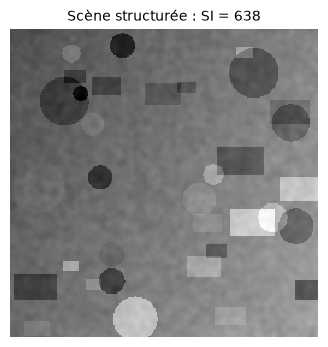

In [16]:
rng_s = np.random.default_rng(7)
t = ndimage.gaussian_filter(rng_s.standard_normal((M, N)), 2)
scene = 0.4 * x / N + 0.2 * y / M + 0.03 * t / t.std()
for _ in range(40):
    cx, cy = rng_s.uniform(0, N, 2); r = rng_s.uniform(6, 22); a = rng_s.uniform(-0.5, 0.5)
    if rng_s.random() < 0.5:
        scene += a * (((x - cx) ** 2 + (y - cy) ** 2) < r ** 2)
    else:
        scene += a * ((np.abs(x - cx) < r) & (np.abs(y - cy) < 0.6 * r))
scene = np.round((scene - scene.min()) / np.ptp(scene) * 255)

fig, ax = plt.subplots(figsize=(4, 4))
show(ax, scene, f"Scène structurée : SI = {sharpness_index(scene):.0f}")
plt.show()

### 7.1 Validation des formules fermées par Monte-Carlo

formule fermée  : mu = 674250.8   sigma = 4878.05
MC u * W        : mu = 674314.5   sigma = 4928.71
MC phase aléat. : mu = 674282.8   sigma = 637.53
TV(u) = 410313.3  ->  z = 54.1 écarts-types sous mu,  SI = 638


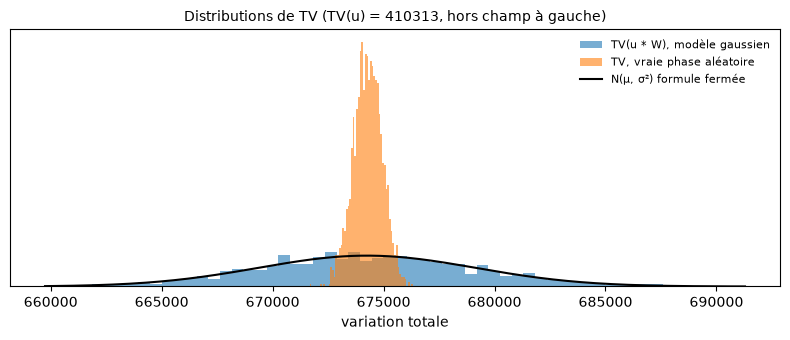

In [17]:
pu = dequantize(perdecomp(scene)[0])  # pré-traitement standard du SI
st = sharpness_stats(pu, pmode=0)
U = np.fft.fft2(pu)

def tv(v):
    return np.abs(np.roll(v, -1, 1) - v).sum() + np.abs(np.roll(v, -1, 0) - v).sum()

K = 2000
tv_gauss = np.array([tv(np.real(np.fft.ifft2(U * np.fft.fft2(rng.standard_normal((M, N)) / np.sqrt(M * N)))))
                     for _ in range(K)])

def phase_aleatoire():
    P = np.fft.fft2(rng.standard_normal((M, N)))  # phase hermitienne aléatoire
    return np.real(np.fft.ifft2(np.abs(U) * P / np.abs(P)))

tv_phase = np.array([tv(phase_aleatoire()) for _ in range(K)])

print(f"formule fermée  : mu = {st['mu']:.1f}   sigma = {st['sigma']:.2f}")
print(f"MC u * W        : mu = {tv_gauss.mean():.1f}   sigma = {tv_gauss.std():.2f}")
print(f"MC phase aléat. : mu = {tv_phase.mean():.1f}   sigma = {tv_phase.std():.2f}")
print(f"TV(u) = {st['tv']:.1f}  ->  z = {st['z']:.1f} écarts-types sous mu,  SI = {st['si']:.0f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(tv_gauss, bins=60, density=True, color="C0", alpha=0.6, label="TV(u * W), modèle gaussien")
ax.hist(tv_phase, bins=60, density=True, color="C1", alpha=0.6, label="TV, vraie phase aléatoire")
t = np.linspace(tv_gauss.min(), tv_gauss.max(), 300)
ax.plot(t, np.exp(-(t - st["mu"]) ** 2 / (2 * st["sigma"] ** 2)) / (st["sigma"] * np.sqrt(2 * np.pi)),
        "k", lw=1.5, label="N(μ, σ²) formule fermée")
ax.set_xlabel("variation totale"); ax.set_yticks([])
ax.legend(frameon=False, fontsize=8); ax.set_title(f"Distributions de TV (TV(u) = {st['tv']:.0f}, hors champ à gauche)")
plt.tight_layout(); plt.show()

Les formules fermées reproduisent exactement le modèle gaussien. La vraie phase aléatoire, à la base de l'indice GPC d'origine, a la **même moyenne** mais une dispersion bien plus faible : seule la phase varie, pas l'amplitude. Le SI est donc **plus prudent** que la GPC. Il sous-estime la significativité, mais l'ordre entre images est préservé. C'est le prix d'un calcul explicite et rapide, sans Monte-Carlo.

### 7.2 Une même scène : le SI ordonne flou et bruit

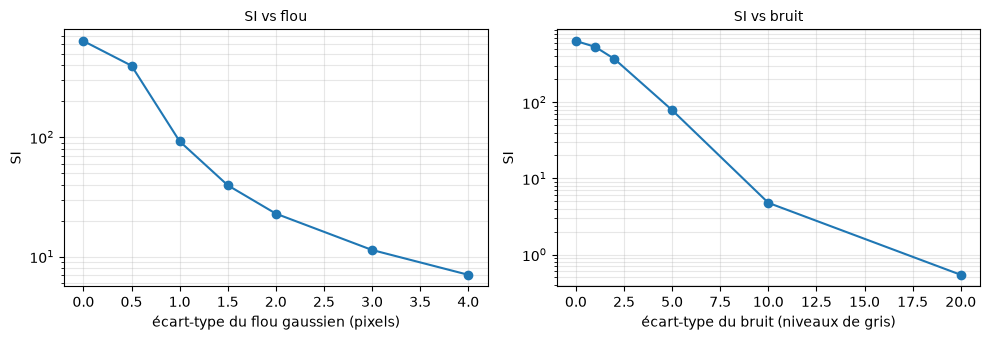

SI flou : [637.8 396.3  92.2  39.5  22.9  11.3   7. ]
SI bruit: [6.378e+02 5.352e+02 3.711e+02 7.890e+01 4.800e+00 5.000e-01]


In [18]:
sigmas = [0, 0.5, 1, 1.5, 2, 3, 4]
bruits = [0, 1, 2, 5, 10, 20]
si_flou = [sharpness_index(ndimage.gaussian_filter(scene, sg)) for sg in sigmas]
si_bruit = [sharpness_index(scene + rng.normal(0, b, scene.shape)) for b in bruits]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].semilogy(sigmas, si_flou, "o-", lw=1.5, ms=6); axs[0].set_xlabel("écart-type du flou gaussien (pixels)")
axs[1].semilogy(bruits, si_bruit, "o-", lw=1.5, ms=6); axs[1].set_xlabel("écart-type du bruit (niveaux de gris)")
for ax in axs: ax.set_ylabel("SI"); ax.grid(alpha=0.3, which="both")
axs[0].set_title("SI vs flou"); axs[1].set_title("SI vs bruit")
plt.tight_layout(); plt.show()
print("SI flou :", np.round(si_flou, 1))
print("SI bruit:", np.round(si_bruit, 1))

Le SI est très sensible : un flou de 0.5 pixel suffit à le diviser nettement. Aux flous forts, la décroissance ralentit. Sur une scène pauvre en contours (texture dominante), l'indice atteint même un **plancher** de quelques unités. Il ne discrimine alors plus rien, et ses variations sont du même ordre que son bruit propre.

### 7.3 Le rôle de la déquantification

In [19]:
for nom, img in [("8 bits", scene), ("16 niveaux", np.round(scene / 16))]:
    print(f"{nom:10s} : SI avec dequant = {sharpness_index(img):7.1f}   sans = {sharpness_index(img, pmode=1):7.1f}")

8 bits     : SI avec dequant =   637.8   sans =  1558.7
16 niveaux : SI avec dequant =   452.5   sans =  2569.4


Les plateaux de valeurs entières identiques donnent des différences exactement nulles. La TV s'en trouve artificiellement abaissée, et le SI **gonflé**. La translation d'un demi-pixel supprime ces plateaux. Ici, `dequant` a un effet réel, contrairement au spectre d'amplitude.

### 7.4 Limites : pas de comparaison entre scènes ni entre tailles

texture aléatoire nette      : SI =    0.4
scène structurée floue (σ=2) : SI =   22.9
image u des §1-6 (texture dominante, nette) : SI =    5.4

imagette  64×64  (densité d'objets constante) : SI =   64.3
imagette 128×128 (densité d'objets constante) : SI =  262.4
imagette 256×256 (densité d'objets constante) : SI =  637.8


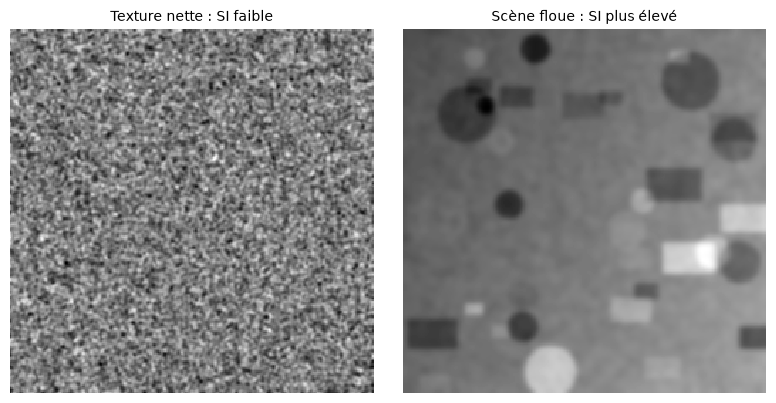

In [20]:
texture = ndimage.gaussian_filter(rng.standard_normal((M, N)), 1.0)
texture = np.round((texture - texture.min()) / np.ptp(texture) * 255)  # nette, mais « aléatoire » (herbe, sable…)
print(f"texture aléatoire nette      : SI = {sharpness_index(texture):6.1f}")
print(f"scène structurée floue (σ=2) : SI = {sharpness_index(ndimage.gaussian_filter(scene, 2)):6.1f}")
print(f"image u des §1-6 (texture dominante, nette) : SI = {sharpness_index(np.round((u - u.min()) / np.ptp(u) * 255)):6.1f}")
print()
for n in (64, 128, 256):
    print(f"imagette {n:3d}×{n:<3d} (densité d'objets constante) : SI = {sharpness_index(scene[:n, :n]):6.1f}")

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
show(axs[0], texture, "Texture nette : SI faible")
show(axs[1], ndimage.gaussian_filter(scene, 2), "Scène floue : SI plus élevé")
plt.tight_layout(); plt.show()

**Conclusion d'usage.** Le SI permet de dire qu'une image est plus nette qu'une autre **lorsqu'il s'agit de la même scène, à la même taille et avec le même pré-traitement** : réglage de mise au point, choix d'une restauration, suivi d'une acquisition. Il ne permet pas de comparer des scènes différentes, car le contenu domine (une texture à phase « aléatoire » a toujours un SI faible). Il ne permet pas non plus de comparer des tailles différentes, puisqu'il croît avec le nombre de pixels. Enfin, ce n'est pas une mesure physique : il ne donne ni FTM ni largeur de PSF.